# Tahap 1

In [ ]:
#@title 1 - Import library
import os
import json
import yaml
import zipfile
import hashlib
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = False

sns.set_theme(style="whitegrid")

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [ ]:
#@title 2 - Ekstrak dataset
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/oil_palm_dataset.zip")
EXTRACT_PATH = Path("/content/oil_palm_dataset")

if not ZIP_PATH.exists():
    raise FileNotFoundError(f"File tidak ditemukan di: {ZIP_PATH}")

EXTRACT_PATH.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset berhasil diekstrak.")
print("Lokasi:", EXTRACT_PATH)

KeyboardInterrupt: 

In [ ]:
#@title 3 - Identifikasi gambar dan file CSV
ROOT = EXTRACT_PATH

SPLITS = ["train", "valid", "test"]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

split_dirs = {
    split: next(
        (p for p in ROOT.rglob(split) if p.is_dir()),
        None
    )
    for split in SPLITS
}

image_files = []
csv_files = {}

for split, folder in split_dirs.items():

    if folder is None:
        print(f"Folder {split} tidak ditemukan.")
        continue

    images = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    csvs = list(folder.glob("*.csv"))

    image_files.extend(images)

    if csvs:
        csv_files[split] = csvs[0]

    print(f"\n{split.upper()}")
    print("Jumlah gambar:", len(images))
    print("CSV:", csvs[0].name if csvs else "Tidak ditemukan")

print("\nTOTAL GAMBAR:", len(image_files))


TRAIN
Jumlah gambar: 5610
CSV: _classes.csv

VALID
Jumlah gambar: 535
CSV: _classes.csv

TEST
Jumlah gambar: 267
CSV: _classes.csv

TOTAL GAMBAR: 6412


# Tahap 2 - Data Cleaning

In [ ]:
#@title Konfigurasi Data Preparation

DATASET_DIR = Path("/content/oil_palm_dataset")
SPLITS = ["train", "valid", "test"]

CLASS_COLUMNS = ["overripe", "ripe", "underripe", "unripe"]

# Ukuran input model
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
RANDOM_STATE = 42

# Folder untuk menyimpan hasil data preparation
PREP_DIR = Path("/content/data_preparation")
PREP_DIR.mkdir(parents=True, exist_ok=True)

# Pastikan struktur dataset tersedia
for split in SPLITS:
    split_dir = DATASET_DIR / split
    if not split_dir.exists():
        raise FileNotFoundError(f"Folder tidak ditemukan: {split_dir}")

    csv_path = split_dir / "_classes.csv"
    if not csv_path.exists():
        raise FileNotFoundError(f"File CSV tidak ditemukan: {csv_path}")

print("Konfigurasi berhasil.")
print("Ukuran input:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Kelas:", CLASS_COLUMNS)

Konfigurasi berhasil.
Ukuran input: (224, 224)
Batch size: 32
Kelas: ['overripe', 'ripe', 'underripe', 'unripe']


In [ ]:
#@title Membaca Anotasi Asli

annotation_list = []

for split in SPLITS:
    csv_path = DATASET_DIR / split / "_classes.csv"

    temp_df = pd.read_csv(csv_path)

    required_columns = ["filename"] + CLASS_COLUMNS
    missing_columns = [
        col for col in required_columns
        if col not in temp_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Kolom tidak ditemukan pada {csv_path}: {missing_columns}"
        )

    temp_df["split"] = split
    temp_df["image_path"] = temp_df["filename"].apply(
        lambda name: str(DATASET_DIR / split / str(name))
    )

    annotation_list.append(temp_df)

df_raw = pd.concat(annotation_list, ignore_index=True)

# Pastikan kolom label bertipe numerik
for col in CLASS_COLUMNS:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

print("Total anotasi:", len(df_raw))
display(df_raw.head())

Total anotasi: 6412


,filename,overripe,ripe,underripe,unripe,split,image_path
0,overripe-331-_jpg.rf.c1763e711e9ef04733e50d111...,1,0,0,0,train,/content/oil_palm_dataset/train/overripe-331-_...
1,ripe-142-_jpg.rf.08f25705cee08800d054de12cc10b...,0,1,0,0,train,/content/oil_palm_dataset/train/ripe-142-_jpg....
2,ripe-320-_jpg.rf.128360b737a545d72dcf2756f5415...,0,1,0,0,train,/content/oil_palm_dataset/train/ripe-320-_jpg....
3,underripe-166-_png.rf.11d7ca27b9d442bf1a518e05...,0,0,1,0,train,/content/oil_palm_dataset/train/underripe-166-...
4,underripe-650-_jpg.rf.f0094e57fc4e11bf3b8822ac...,0,0,0,0,train,/content/oil_palm_dataset/train/underripe-650-...


In [ ]:
#@title Audit Missing Values dan Label

# Periksa missing values pada kolom penting
missing_report = df_raw[
    ["filename"] + CLASS_COLUMNS
].isnull().sum().reset_index()

missing_report.columns = ["kolom", "jumlah_missing"]
missing_report["persentase"] = (
    missing_report["jumlah_missing"] / len(df_raw) * 100
)

display(missing_report)

# Hitung jumlah label aktif pada setiap baris
df_raw["active_labels"] = df_raw[CLASS_COLUMNS].sum(axis=1)

# Klasifikasi status label
df_raw["label_status"] = np.select(
    [
        df_raw[CLASS_COLUMNS].isnull().any(axis=1),
        df_raw["active_labels"] == 0,
        df_raw["active_labels"] == 1,
        df_raw["active_labels"] > 1
    ],
    [
        "missing",
        "all_zero",
        "valid",
        "multi_label"
    ],
    default="invalid"
)

label_status_report = (
    df_raw["label_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="jumlah")
)

label_status_report["persentase"] = (
    label_status_report["jumlah"] / len(df_raw) * 100
)

display(label_status_report)

print("Total anotasi:", len(df_raw))
print("Label valid:", (df_raw["label_status"] == "valid").sum())
print("Label tidak valid:", (df_raw["label_status"] != "valid").sum())

,kolom,jumlah_missing,persentase
0,filename,0,0.0
1,overripe,0,0.0
2,ripe,0,0.0
3,underripe,0,0.0
4,unripe,0,0.0


,status,jumlah,persentase
0,valid,5790,90.299439
1,multi_label,480,7.485964
2,all_zero,142,2.214598


Total anotasi: 6412
Label valid: 5790
Label tidak valid: 622


In [ ]:
#@title Validasi File Gambar

def check_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

df_raw["image_exists"] = df_raw["image_path"].apply(
    lambda path: Path(path).is_file()
)

df_raw["image_readable"] = df_raw["image_path"].apply(
    lambda path: check_image(path) if Path(path).is_file() else False
)

image_audit = pd.DataFrame({
    "status": [
        "File ditemukan",
        "File tidak ditemukan",
        "Gambar dapat dibaca",
        "Gambar rusak/tidak dapat dibaca"
    ],
    "jumlah": [
        df_raw["image_exists"].sum(),
        (~df_raw["image_exists"]).sum(),
        df_raw["image_readable"].sum(),
        (~df_raw["image_readable"]).sum()
    ]
})

display(image_audit)

,status,jumlah
0,File ditemukan,6412
1,File tidak ditemukan,0
2,Gambar dapat dibaca,6412
3,Gambar rusak/tidak dapat dibaca,0


In [ ]:
#@title Membentuk Dataset Bersih

df_clean = df_raw[
    (df_raw["label_status"] == "valid") &
    (df_raw["image_exists"]) &
    (df_raw["image_readable"])
].copy()

# Tentukan label hanya setelah validasi One-Hot
df_clean["label"] = df_clean[CLASS_COLUMNS].idxmax(axis=1)

# Pastikan satu gambar tidak tercatat berulang dalam split yang sama
df_clean["filename_key"] = (
    df_clean["split"].astype(str) + "/" +
    df_clean["filename"].astype(str)
)

duplicate_filename_count = df_clean["filename_key"].duplicated().sum()

print("Total anotasi awal :", len(df_raw))
print("Total data bersih  :", len(df_clean))
print("Data dikeluarkan   :", len(df_raw) - len(df_clean))
print("Duplikat filename  :", duplicate_filename_count)

display(df_clean[["filename", "split", "label"]].head())

Total anotasi awal : 6412
Total data bersih  : 5790
Data dikeluarkan   : 622
Duplikat filename  : 0


,filename,split,label
0,overripe-331-_jpg.rf.c1763e711e9ef04733e50d111...,train,overripe
1,ripe-142-_jpg.rf.08f25705cee08800d054de12cc10b...,train,ripe
2,ripe-320-_jpg.rf.128360b737a545d72dcf2756f5415...,train,ripe
3,underripe-166-_png.rf.11d7ca27b9d442bf1a518e05...,train,underripe
5,ripe-33-_jpg.rf.baa6b566a7a95572efd4b721590533...,train,ripe


In [ ]:
#@title Pemeriksaan Duplikasi SHA-256

def calculate_sha256(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

df_clean["sha256"] = df_clean["image_path"].apply(calculate_sha256)

duplicate_hashes = df_clean[
    df_clean.duplicated("sha256", keep=False)
].sort_values("sha256")

print("Total gambar bersih :", len(df_clean))
print("Jumlah hash unik    :", df_clean["sha256"].nunique())
print("Jumlah gambar duplikat:", len(duplicate_hashes))

if len(duplicate_hashes) > 0:
    display(
        duplicate_hashes[
            ["filename", "split", "sha256"]
        ].head(20)
    )
else:
    print("Tidak ditemukan gambar identik berdasarkan SHA-256.")

# Periksa apakah duplikasi ditemukan pada split berbeda
cross_split_duplicates = (
    duplicate_hashes.groupby("sha256")["split"].nunique()
)

print(
    "Kelompok duplikat lintas split:",
    (cross_split_duplicates > 1).sum()
)

Total gambar bersih : 5790
Jumlah hash unik    : 5790
Jumlah gambar duplikat: 0
Tidak ditemukan gambar identik berdasarkan SHA-256.
Kelompok duplikat lintas split: 0


Batas bawah: 44.47 KB
Batas atas : 175.08 KB
Jumlah outlier: 74
Persentase outlier: 1.28 %


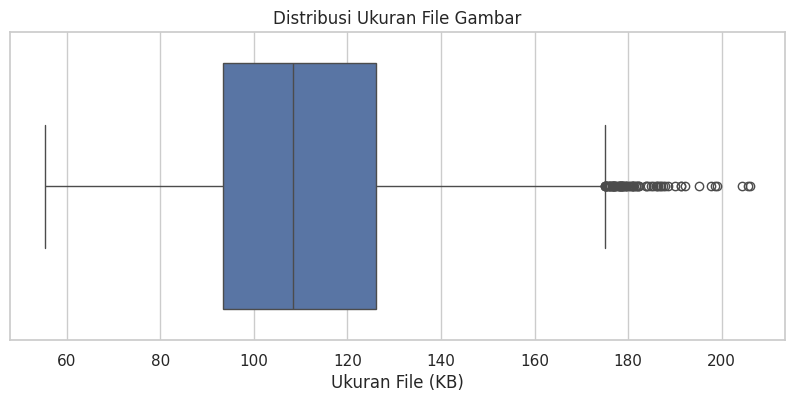

In [ ]:
#@title Pemeriksaan Outlier Ukuran File

df_clean["file_size_kb"] = df_clean["image_path"].apply(
    lambda path: Path(path).stat().st_size / 1024
)

Q1 = df_clean["file_size_kb"].quantile(0.25)
Q3 = df_clean["file_size_kb"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean["is_size_outlier"] = (
    (df_clean["file_size_kb"] < lower_bound) |
    (df_clean["file_size_kb"] > upper_bound)
)

print("Batas bawah:", round(lower_bound, 2), "KB")
print("Batas atas :", round(upper_bound, 2), "KB")
print("Jumlah outlier:", df_clean["is_size_outlier"].sum())
print(
    "Persentase outlier:",
    round(df_clean["is_size_outlier"].mean() * 100, 2), "%"
)

plt.figure(figsize=(10, 4))
sns.boxplot(x=df_clean["file_size_kb"])
plt.title("Distribusi Ukuran File Gambar")
plt.xlabel("Ukuran File (KB)")
plt.show()

In [ ]:
#@title Ekstraksi Fitur Metadata Gambar

def extract_image_features(path):
    with Image.open(path) as img:
        width, height = img.size
        img_rgb = img.convert("RGB")

        img_array = np.asarray(img_rgb, dtype=np.float32)

        return {
            "width": width,
            "height": height,
            "aspect_ratio": width / height if height != 0 else 0,
            "mean_red": img_array[:, :, 0].mean(),
            "mean_green": img_array[:, :, 1].mean(),
            "mean_blue": img_array[:, :, 2].mean()
        }

feature_data = df_clean["image_path"].apply(
    extract_image_features
).apply(pd.Series)

df_clean = pd.concat(
    [df_clean.reset_index(drop=True),
     feature_data.reset_index(drop=True)],
    axis=1
)

display(
    df_clean[
        [
            "filename", "label", "width", "height",
            "aspect_ratio", "mean_red", "mean_green", "mean_blue"
        ]
    ].head()
)

,filename,label,width,height,aspect_ratio,mean_red,mean_green,mean_blue
0,overripe-331-_jpg.rf.c1763e711e9ef04733e50d111...,overripe,640.0,640.0,1.0,77.390511,65.748520,61.977142
1,ripe-142-_jpg.rf.08f25705cee08800d054de12cc10b...,ripe,640.0,640.0,1.0,75.462288,62.312691,68.215454
2,ripe-320-_jpg.rf.128360b737a545d72dcf2756f5415...,ripe,640.0,640.0,1.0,106.618515,93.732513,92.259865
3,underripe-166-_png.rf.11d7ca27b9d442bf1a518e05...,underripe,640.0,640.0,1.0,121.242958,103.201614,103.231728
4,ripe-33-_jpg.rf.baa6b566a7a95572efd4b721590533...,ripe,640.0,640.0,1.0,82.095497,69.442528,60.076073


In [ ]:
#@title Ringkasan Fitur Gambar

feature_columns = [
    "width",
    "height",
    "aspect_ratio",
    "mean_red",
    "mean_green",
    "mean_blue"
]

display(df_clean[feature_columns].describe().T)

print("Jumlah fitur metadata:", len(feature_columns))
print("Fitur utama untuk model: nilai piksel citra RGB")

,count,mean,std,min,25%,50%,75%,max
width,5790.0,640.000000,0.000000,640.000000,640.000000,640.000000,640.000000,640.000000
height,5790.0,640.000000,0.000000,640.000000,640.000000,640.000000,640.000000,640.000000
aspect_ratio,5790.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
mean_red,5790.0,115.115168,25.162542,38.205715,97.743170,122.793350,129.983391,182.639023
mean_green,5790.0,102.157475,25.384955,25.415386,84.188808,107.203087,119.024073,171.302017
mean_blue,5790.0,93.443116,25.814572,21.551023,74.023054,95.431454,113.106665,169.196243


Jumlah fitur metadata: 6
Fitur utama untuk model: nilai piksel citra RGB


## Data Transformation

In [ ]:
#@title Import TensorFlow dan Scikit-learn

import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
#@title Label Encoding

CLASS_NAMES = ["overripe", "ripe", "underripe", "unripe"]

class_to_index = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

df_clean["label_encoded"] = df_clean["label"].map(class_to_index)

if df_clean["label_encoded"].isnull().any():
    raise ValueError("Ditemukan label yang tidak termasuk CLASS_NAMES.")

df_clean["label_encoded"] = df_clean["label_encoded"].astype("int32")

print("Mapping label:")
print(class_to_index)

display(
    df_clean[["filename", "label", "label_encoded"]].head()
)

Mapping label:
{'overripe': 0, 'ripe': 1, 'underripe': 2, 'unripe': 3}


,filename,label,label_encoded
0,overripe-331-_jpg.rf.c1763e711e9ef04733e50d111...,overripe,0
1,ripe-142-_jpg.rf.08f25705cee08800d054de12cc10b...,ripe,1
2,ripe-320-_jpg.rf.128360b737a545d72dcf2756f5415...,ripe,1
3,underripe-166-_png.rf.11d7ca27b9d442bf1a518e05...,underripe,2
4,ripe-33-_jpg.rf.baa6b566a7a95572efd4b721590533...,ripe,1


In [ ]:
#@title Fungsi Preprocessing Citra

def preprocess_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize gambar
    image = tf.image.resize(
        image,
        IMG_SIZE,
        method="bilinear"
    )

    # Normalisasi piksel dari 0-255 menjadi 0-1
    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.int32)

    return image, label


print("Fungsi preprocessing berhasil dibuat.")

Fungsi preprocessing berhasil dibuat.


In [ ]:
#@title Data Augmentation

data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip(
            mode="horizontal_and_vertical"
        ),
        tf.keras.layers.RandomRotation(
            factor=0.04
        ),
        tf.keras.layers.RandomZoom(
            height_factor=0.10,
            width_factor=0.10
        ),
        tf.keras.layers.RandomContrast(
            factor=0.10
        )
    ],
    name="data_augmentation"
)

print("Layer augmentasi berhasil dibuat.")

Layer augmentasi berhasil dibuat.


In [ ]:
#@title Membuat Pipeline Dataset

def create_tf_dataset(dataframe, training=False):
    paths = dataframe["image_path"].astype(str).values
    labels = dataframe["label_encoded"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [ ]:
#@title Membentuk Dataset Training, Validation, dan Test

train_df = df_clean[df_clean["split"] == "train"].copy()
valid_df = df_clean[df_clean["split"] == "valid"].copy()
test_df  = df_clean[df_clean["split"] == "test"].copy()

print("Jumlah data setelah cleaning:")
print("Training   :", len(train_df))
print("Validation :", len(valid_df))
print("Testing    :", len(test_df))
print("Total      :", len(train_df) + len(valid_df) + len(test_df))

# Pastikan ketiga split memiliki data
assert len(train_df) > 0, "Data training kosong."
assert len(valid_df) > 0, "Data validation kosong."
assert len(test_df) > 0, "Data testing kosong."

# Persentase pembagian data setelah cleaning
split_summary = pd.DataFrame({
    "split": ["train", "valid", "test"],
    "jumlah": [
        len(train_df),
        len(valid_df),
        len(test_df)
    ]
})

split_summary["persentase"] = (
    split_summary["jumlah"] /
    split_summary["jumlah"].sum() * 100
)

display(split_summary)

Jumlah data setelah cleaning:
Training   : 5074
Validation : 474
Testing    : 242
Total      : 5790


,split,jumlah,persentase
0,train,5074,87.633851
1,valid,474,8.186528
2,test,242,4.179620


In [ ]:
#@title Membuat Dataset TensorFlow

train_dataset = create_tf_dataset(
    train_df,
    training=True
)

valid_dataset = create_tf_dataset(
    valid_df,
    training=False
)

test_dataset = create_tf_dataset(
    test_df,
    training=False
)

print("Pipeline dataset berhasil dibuat.")

Pipeline dataset berhasil dibuat.


Bentuk batch gambar : (32, 224, 224, 3)
Bentuk batch label  : (32,)
Nilai piksel minimum: 0.0
Nilai piksel maksimum: 1.0
Tipe data gambar    : <dtype: 'float32'>
Tipe data label     : <dtype: 'int32'>


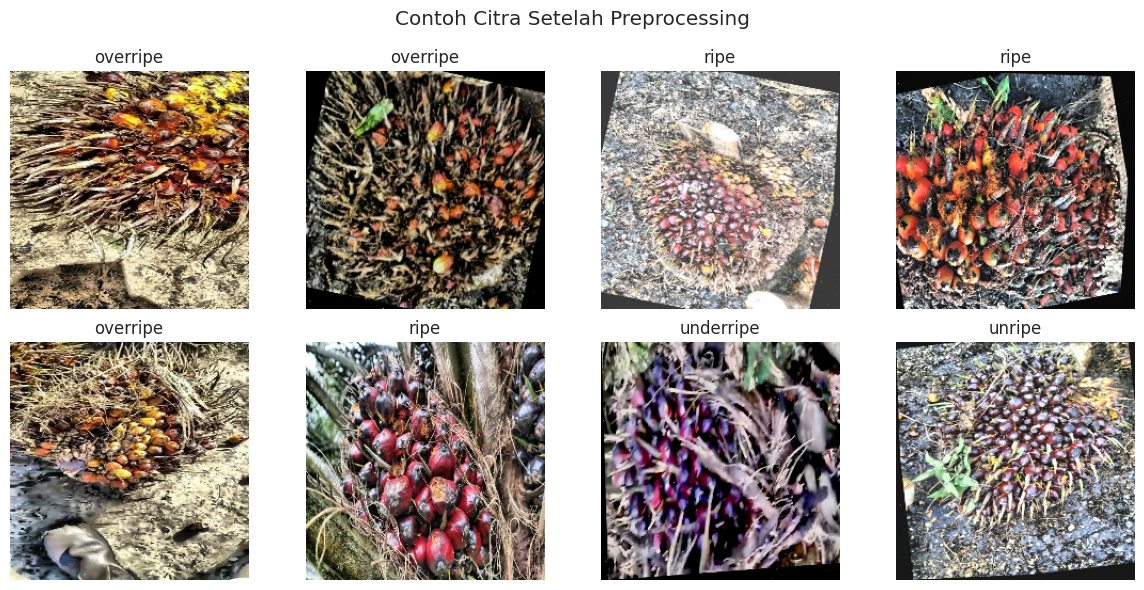

In [ ]:
#@title Validasi Hasil Preprocessing

images, labels = next(iter(train_dataset))

print("Bentuk batch gambar :", images.shape)
print("Bentuk batch label  :", labels.shape)
print("Nilai piksel minimum:", float(tf.reduce_min(images)))
print("Nilai piksel maksimum:", float(tf.reduce_max(images)))
print("Tipe data gambar    :", images.dtype)
print("Tipe data label     :", labels.dtype)

# Visualisasi beberapa gambar hasil preprocessing
plt.figure(figsize=(12, 6))

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].numpy())

    label_index = int(labels[i].numpy())
    plt.title(index_to_class[label_index])
    plt.axis("off")

plt.suptitle("Contoh Citra Setelah Preprocessing")
plt.tight_layout()
plt.show()

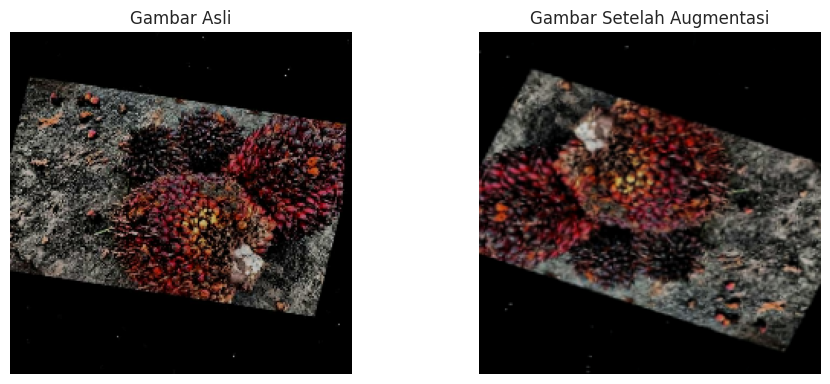

In [ ]:
#@title Visualisasi Data Augmentation

sample_images, sample_labels = next(iter(train_dataset))

sample_image = sample_images[0:1]

augmented_images = data_augmentation(
    sample_image,
    training=True
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_image[0].numpy())
plt.title("Gambar Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_images[0].numpy())
plt.title("Gambar Setelah Augmentasi")
plt.axis("off")

plt.tight_layout()
plt.show()

##Data Splitting

label,overripe,ripe,underripe,unripe
split,,,,
train,1392,1431,1237,1014
valid,136,128,118,92
test,78,61,55,48


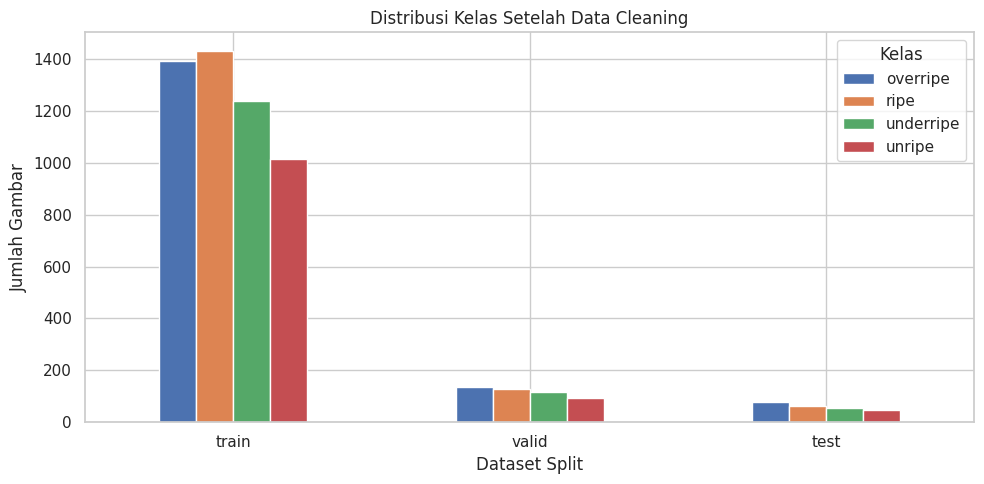

In [ ]:
#@title Distribusi Kelas Setiap Split

split_class_distribution = (
    df_clean.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=SPLITS, columns=CLASS_NAMES, fill_value=0)
)

display(split_class_distribution)

# Visualisasi distribusi kelas
split_class_distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribusi Kelas Setelah Data Cleaning")
plt.xlabel("Dataset Split")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=0)
plt.legend(title="Kelas")
plt.tight_layout()
plt.show()

In [ ]:
#@title Proporsi Data Splitting

total_clean_data = len(df_clean)

for split in SPLITS:
    jumlah = len(df_clean[df_clean["split"] == split])
    persentase = jumlah / total_clean_data * 100

    print(
        f"{split.capitalize():12s}: "
        f"{jumlah:5d} gambar ({persentase:.2f}%)"
    )

Train       :  5074 gambar (87.63%)
Valid       :   474 gambar (8.19%)
Test        :   242 gambar (4.18%)


##Data Balancing

In [ ]:
#@title Distribusi Kelas Training

train_class_counts = (
    train_df["label"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

display(
    train_class_counts.reset_index().rename(
        columns={
            "index": "kelas",
            "label": "jumlah"
        }
    )
)

imbalance_ratio = (
    train_class_counts.max() / train_class_counts.min()
    if train_class_counts.min() > 0
    else np.inf
)

print("Imbalance ratio:", round(imbalance_ratio, 3))

,jumlah,count
0,overripe,1392
1,ripe,1431
2,underripe,1237
3,unripe,1014


Imbalance ratio: 1.411


In [ ]:
#@title Menghitung Class Weights

classes = np.array(sorted(train_df["label_encoded"].unique()))

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label_encoded"].values
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

class_weights_readable = {
    index_to_class[class_id]: weight
    for class_id, weight in class_weights.items()
}

print("Class weights:")
for class_name, weight in class_weights_readable.items():
    print(f"{class_name:12s}: {weight:.4f}")

Class weights:
overripe    : 0.9113
ripe        : 0.8864
underripe   : 1.0255
unripe      : 1.2510


In [ ]:
#@title Ringkasan Data Preparation

summary_preparation = pd.DataFrame({
    "Tahapan": [
        "Total anotasi awal",
        "Label valid One-Hot",
        "Label tidak valid",
        "Gambar tidak ditemukan",
        "Gambar tidak dapat dibaca",
        "Total data setelah cleaning",
        "Data training",
        "Data validation",
        "Data testing",
        "Jumlah kelas"
    ],
    "Hasil": [
        len(df_raw),
        (df_raw["label_status"] == "valid").sum(),
        (df_raw["label_status"] != "valid").sum(),
        (~df_raw["image_exists"]).sum(),
        (~df_raw["image_readable"]).sum(),
        len(df_clean),
        len(train_df),
        len(valid_df),
        len(test_df),
        len(CLASS_NAMES)
    ]
})

display(summary_preparation)

# Simpan hasil data preparation
df_clean.to_csv(
    PREP_DIR / "cleaned_dataset_metadata.csv",
    index=False
)

split_class_distribution.to_csv(
    PREP_DIR / "class_distribution_by_split.csv"
)

summary_preparation.to_csv(
    PREP_DIR / "preparation_summary.csv",
    index=False
)

print("Laporan tersimpan di:", PREP_DIR)

,Tahapan,Hasil
0,Total anotasi awal,6412
1,Label valid One-Hot,5790
2,Label tidak valid,622
3,Gambar tidak ditemukan,0
4,Gambar tidak dapat dibaca,0
5,Total data setelah cleaning,5790
6,Data training,5074
7,Data validation,474
8,Data testing,242
9,Jumlah kelas,4


Laporan tersimpan di: /content/data_preparation


In [ ]:
#@title Menyimpan Konfigurasi Data Preparation

preparation_config = {
    "dataset": "Oil Palm FFB Ripeness",
    "classes": CLASS_NAMES,
    "initial_annotations": int(len(df_raw)),
    "cleaned_images": int(len(df_clean)),
    "image_size": list(IMG_SIZE),
    "color_space": "RGB",
    "normalization": "Pixel values divided by 255 (0-1)",
    "batch_size": BATCH_SIZE,
    "splitting_strategy": "Predefined Roboflow train/valid/test",
    "augmentation": [
        "Random horizontal and vertical flip",
        "Random rotation",
        "Random zoom",
        "Random contrast"
    ],
    "balancing": "Class weights",
    "random_state": RANDOM_STATE
}

with open(
    PREP_DIR / "preparation_config.json",
    "w"
) as file:
    json.dump(preparation_config, file, indent=4)

print("Konfigurasi berhasil disimpan.")

Konfigurasi berhasil disimpan.
